# HUMAN RIBOFLOW FILTER: v2 vs v3

RiboFlow aligns reads to the filter before the transcriptome and discards the reads that align.
Here we compare the sequences in the human v2 and v3 filters. `compare_v2_and_v3_alignment.ipynb`
compares how the two filters handle real reads.

v2 has hg19 UCSC tRNAs, five rRNA sequences, and five snRNA pseudogene and repeat sequences.
v3 is rebuilt from current sources (see `filter/human/v3/README.md`):

* nuclear tRNAs from GtRNAdb hg38, high-confidence set only
* nuclear rRNAs from NCBI RefSeq (45S, 18S, 28S, 5.8S and 5S)
* mitochondrial rRNAs and tRNAs from NCBI RefSeq (`NC_012920.1`), new in v3
* the five snRNA pseudogene and repeat sequences from v2

In [1]:
import gzip
import hashlib
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

%matplotlib inline

Filter files:

In [2]:
REPO = "../../../.."   # repo root
v2_fasta = f"{REPO}/filter/human/v2/human_rtRNA.fa.gz"
v3_fasta = f"{REPO}/filter/human/v3/human_rtRNA.fa.gz"

## Loading

v3 names are `source|accession|symbol`, so the first field gives the category. v2 names are in
UCSC style, so we classify them from the name.

In [3]:
def read_fasta(path):
    opener = gzip.open if path.endswith(".gz") else open
    header, seq = None, []
    with opener(path, "rt") as fh:
        for line in fh:
            if line.startswith(">"):
                if header is not None:
                    yield header, "".join(seq)
                header, seq = line[1:].strip(), []
            else:
                seq.append(line.strip())
    if header is not None:
        yield header, "".join(seq)

def v3_category(header):
    return header.split("|")[0]

def v2_category(header):
    tok = header.split()[0]
    if tok.startswith("rRNA"):               return "nuclear_rRNA"
    if "rmsk" in tok:                         return "repeat"
    if "RNU" in tok or "RN7SK" in tok:        return "snRNA_pseudogene"
    return "nuclear_tRNA"

v2 = [(h, s) for h, s in read_fasta(v2_fasta)]
v3 = [(h, s) for h, s in read_fasta(v3_fasta)]
print("v2 records:", len(v2), " v3 records:", len(v3))

v2 records: 635  v3 records: 498


## Composition

,v2,v3
nuclear rRNA,5,37
mitochondrial rRNA/tRNA,0,24
nuclear tRNA,625,432
snRNA-pseudogene/repeat,5,5


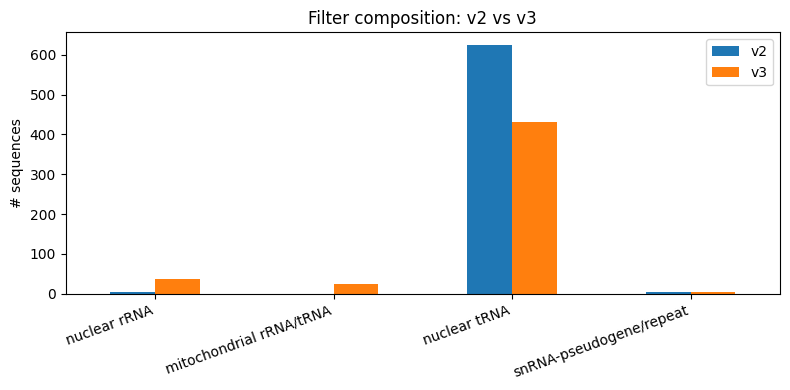

In [4]:
COARSE = {
    "ncbi_rRNA": "nuclear rRNA", "ncbi_mt": "mitochondrial rRNA/tRNA",
    "gtrnadb_tRNA": "nuclear tRNA", "v2": "snRNA-pseudogene/repeat",
    "nuclear_rRNA": "nuclear rRNA", "nuclear_tRNA": "nuclear tRNA",
    "repeat": "snRNA-pseudogene/repeat", "snRNA_pseudogene": "snRNA-pseudogene/repeat",
}
CLASSES = ["nuclear rRNA", "mitochondrial rRNA/tRNA", "nuclear tRNA", "snRNA-pseudogene/repeat"]

def compose(records, catfn):
    c = defaultdict(int)
    for h, _ in records:
        c[COARSE[catfn(h)]] += 1
    return [c.get(k, 0) for k in CLASSES]

comp = pd.DataFrame({"v2": compose(v2, v2_category), "v3": compose(v3, v3_category)}, index=CLASSES)
display(comp)

comp.plot.bar(figsize=(8, 4)); plt.ylabel("# sequences"); plt.title("Filter composition: v2 vs v3");
plt.xticks(rotation=20, ha="right"); plt.tight_layout();

## Sequence overlap

v3 is not a superset of v2. The nuclear tRNAs come from hg38 instead of hg19, and the rRNAs come
from RefSeq. We compare unique sequences, so identical tRNA copies count once.

v2: 635 records, 469 unique sequences
v3: 498 records, 313 unique sequences
shared unique sequences: 261
only in v2: 208   only in v3: 52


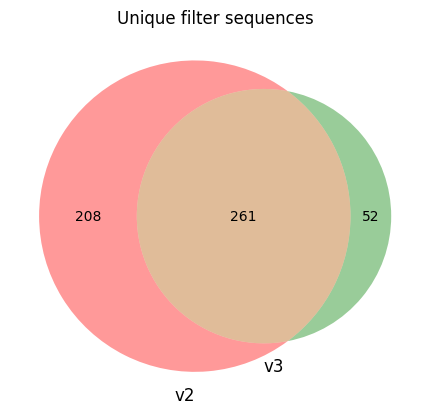

In [5]:
def hashes(records):
    return {hashlib.md5(s.encode()).hexdigest() for _, s in records}

h2, h3 = hashes(v2), hashes(v3)
print(f"v2: {len(v2)} records, {len(h2)} unique sequences")
print(f"v3: {len(v3)} records, {len(h3)} unique sequences")
print(f"shared unique sequences: {len(h2 & h3)}")
print(f"only in v2: {len(h2 - h3)}   only in v3: {len(h3 - h2)}")

venn2([h2, h3], set_labels=("v2", "v3"));
plt.title("Unique filter sequences");

## What changed, by category

In [6]:
def cat_of(records, catfn):
    d = {}
    for h, s in records:
        d.setdefault(hashlib.md5(s.encode()).hexdigest(), COARSE[catfn(h)])
    return d

v2cat = cat_of(v2, v2_category)
v3cat = cat_of(v3, v3_category)

only_v2 = defaultdict(int)
for x in (h2 - h3): only_v2[v2cat[x]] += 1
only_v3 = defaultdict(int)
for x in (h3 - h2): only_v3[v3cat[x]] += 1

print(f"unique sequences only in v2 ({len(h2 - h3)}):")
for k in CLASSES:
    if only_v2.get(k): print(f"  {k}: {only_v2[k]}")
print(f"\nunique sequences only in v3 ({len(h3 - h2)}):")
for k in CLASSES:
    if only_v3.get(k): print(f"  {k}: {only_v3[k]}")

unique sequences only in v2 (208):
  nuclear rRNA: 4
  nuclear tRNA: 204

unique sequences only in v3 (52):
  nuclear rRNA: 15
  mitochondrial rRNA/tRNA: 24
  nuclear tRNA: 13


## Length distribution

Lengths go from about 70 nt (tRNAs) to 13 kb (45S), so we use a log scale.

v2 length min/median/max: 68 73 13357
v3 length min/median/max: 59 73 13373


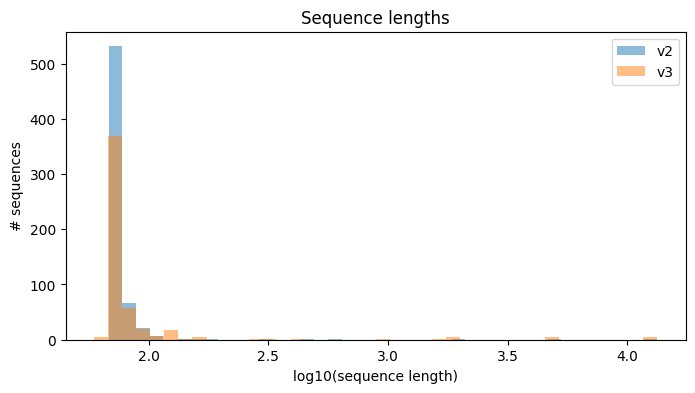

In [7]:
lens_v2 = np.array([len(s) for _, s in v2])
lens_v3 = np.array([len(s) for _, s in v3])

plt.figure(figsize=(8, 4))
plt.hist(np.log10(lens_v2), bins=40, alpha=0.5, label="v2")
plt.hist(np.log10(lens_v3), bins=40, alpha=0.5, label="v3")
plt.xlabel("log10(sequence length)"); plt.ylabel("# sequences"); plt.legend(); plt.title("Sequence lengths");

print("v2 length min/median/max:", lens_v2.min(), int(np.median(lens_v2)), lens_v2.max())
print("v3 length min/median/max:", lens_v3.min(), int(np.median(lens_v3)), lens_v3.max())

## Mitochondrial sequences (new in v3)

In [8]:
mt = [(h, s) for h, s in v3 if v3_category(h) == "ncbi_mt"]
print(f"{len(mt)} mitochondrial sequences")
for h, s in mt:
    _, loc, sym = h.split("|")
    print(f"  {sym:9} {len(s):>5} nt   {loc}")

24 mitochondrial sequences
  MT-RNR1     954 nt   NC_012920.1:648-1601
  MT-RNR2    1559 nt   NC_012920.1:1671-3229
  MT-TA        69 nt   NC_012920.1:5655-5587
  MT-TC        66 nt   NC_012920.1:5826-5761
  MT-TD        68 nt   NC_012920.1:7518-7585
  MT-TE        69 nt   NC_012920.1:14742-14674
  MT-TF        71 nt   NC_012920.1:577-647
  MT-TG        68 nt   NC_012920.1:9991-10058
  MT-TH        69 nt   NC_012920.1:12138-12206
  MT-TI        69 nt   NC_012920.1:4263-4331
  MT-TK        70 nt   NC_012920.1:8295-8364
  MT-TL1       75 nt   NC_012920.1:3230-3304
  MT-TL2       71 nt   NC_012920.1:12266-12336
  MT-TM        68 nt   NC_012920.1:4402-4469
  MT-TN        73 nt   NC_012920.1:5729-5657
  MT-TP        68 nt   NC_012920.1:16023-15956
  MT-TQ        72 nt   NC_012920.1:4400-4329
  MT-TR        65 nt   NC_012920.1:10405-10469
  MT-TS1       69 nt   NC_012920.1:7514-7446
  MT-TS2       59 nt   NC_012920.1:12207-12265
  MT-TT        66 nt   NC_012920.1:15888-15953
  MT-TV        6

## Summary

v3 has 498 sequences (313 unique) and v2 has 635 (469 unique). They share 261 unique sequences.

The nuclear tRNAs changed from hg19 to the GtRNAdb hg38 high-confidence set, and the rRNAs come
from NCBI RefSeq instead of the five v2 sequences. v3 adds 24 mitochondrial rRNAs and tRNAs and
keeps the five snRNA pseudogene and repeat sequences from v2.

## Files

* v3 filter: `filter/human/v3/human_rtRNA.fa.gz` and its Bowtie2 index, built by
  `filter/human/v3/scripts/build_filter_v3.py` from `filter/human/v3/raw/`
* v2 filter: `filter/human/v2/human_rtRNA.fa.gz` and its Bowtie2 index